# Cell-coverage comparison

This notebook compares the image-derived **coverage percentage** (the fraction of the image area occupied by the segmented mask, expressed as a percentage) across any experimental groups.

The analysis proceeds in five steps:

1. **Data quality control** &mdash; merge the per-group tables and report exact duplicate rows.
2. **Outlier screening** &mdash; flag outlying values within each group using Tukey's 1.5&times;IQR fences.
3. **Descriptive statistics** &mdash; mean, standard deviation, median and quartiles per group.
4. **Hypothesis testing** &mdash; Kruskal&ndash;Wallis omnibus test followed by pairwise two-sided permutation tests with Holm correction for multiple comparisons.
5. **Effect sizes and visualisation** &mdash; Cohen's *d*, bootstrap confidence intervals for the mean difference, and box/swarm plots.

All numerical results are reproducible: random draws (permutations and bootstrap resamples) use a fixed seed.


## Requirements

Python 3.9 with `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib` and `seaborn`. The data files `cells/data_2624.csv`, `cells/data_3841.csv` and `cells/data_AMPS22.csv` must be located in a `cells/` folder next to this notebook.


In [1]:
# Standard scientific Python stack
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility and simulation settings
RNG_SEED = 42
N_PERMUTATIONS = 100_000   # permutations per pairwise test
N_BOOTSTRAP = 100_000      # bootstrap resamples per effect-size CI
ALPHA = 0.05               # family-wise significance level

# Smallest p-value resolvable with a finite number of permutations; the
# add-one correction (Phipson & Smyth, 2010) means p >= 1 / (N + 1).
P_VALUE_FLOOR = 1.0 / (N_PERMUTATIONS + 1)

# The per-group CSVs live in a `cells/` folder next to this notebook.
DATA_DIR = Path('cells')

# Plotting style
sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)


In [2]:
# Load the per-group tables and stack them into one long-form table.
# Each row is a single analysed image: total pixels, mask pixels, the derived
# coverage percentage and the number of objects detected.
CSV_FILES = ['data_2624.csv', 'data_3841.csv', 'data_AMPS22.csv']

data_raw = pd.concat(
    [pd.read_csv(DATA_DIR / f) for f in CSV_FILES],
    ignore_index=True,   # rebuild a clean 0..N-1 index
)

print('Merged data shape:', data_raw.shape)
print()
print('Observations per group (raw):')
print(data_raw['File Name'].value_counts().to_string())


Merged data shape: (446, 5)

Observations per group (raw):
File Name
Carioca+AMPS22    150
Carioca+2624      148
Carioca+3841      148


In [3]:
# Data-quality check: report exact duplicate rows before any filtering.
# Exact duplicates are usually accidental (a row saved twice); verify them
# against the raw images before deciding whether they are genuine repeated
# measurements.
duplicated = data_raw.duplicated(keep=False)
dup_rows = data_raw[duplicated]
n_dup_rows = int(dup_rows.shape[0])                        # every occurrence involved
n_distinct = int(dup_rows.drop_duplicates().shape[0])      # distinct duplicated rows
print(f'Rows involved in exact duplication: {n_dup_rows} '
      f'({n_distinct} distinct rows appear more than once)')
if n_dup_rows:
    print(dup_rows.sort_values(['File Name', 'Coverage Percentage'])
          .to_string(index=False))
    

Rows involved in exact duplication: 4 (2 distinct rows appear more than once)
   File Name  Total Pixels  Mask Pixels  Coverage Percentage  Objects Detected
Carioca+3841       6076416      3272655              53.8583                33
Carioca+3841       6076416      3272655              53.8583                33
Carioca+3841       6076416      3370531              55.4691                31
Carioca+3841       6076416      3370531              55.4691                31


In [4]:
# Duplicate rows removed
data_raw = data_raw.drop_duplicates()


In [5]:
# Outlier screening within each group using Tukey's fences (1.5 x IQR;
# Tukey, 1977). Flagged observations are removed for the primary analysis;
# a sensitivity analysis on the unfiltered data (below) confirms that this
# choice does not change any conclusion.

def iqr_fences(series, k=1.5):
    """Lower and upper Tukey fences of a series."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

grouped = data_raw.groupby('File Name')['Coverage Percentage']
low = grouped.transform(lambda s: iqr_fences(s)[0])
high = grouped.transform(lambda s: iqr_fences(s)[1])
is_outlier = (data_raw['Coverage Percentage'] < low) | (data_raw['Coverage Percentage'] > high)

print('Outliers flagged per group:')
print(data_raw[is_outlier]
      .groupby('File Name')['Coverage Percentage']
      .agg(count='count', min='min', max='max')
      .to_string())

# Primary dataset: outliers removed.
data = data_raw[~is_outlier].reset_index(drop=True)
print()
print('Observations per group after outlier removal:')
print(data['File Name'].value_counts().to_string())


Outliers flagged per group:
                count      min     max
File Name                             
Carioca+AMPS22      2  59.9482  60.027

Observations per group after outlier removal:
File Name
Carioca+2624      148
Carioca+AMPS22    148
Carioca+3841      146


In [6]:
# Descriptive statistics of the primary (outlier-removed) dataset.
summary = (
    data.groupby('File Name')['Coverage Percentage']
    .agg(
        n='count',
        mean='mean',
        sd='std',
        median='median',
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        min='min',
        max='max',
    )
)
print(summary.round(3).to_string())


                  n    mean      sd  median      q1      q3     min     max
File Name                                                                  
Carioca+2624    148  68.100   9.489  67.817  60.174  75.931  47.262  87.876
Carioca+3841    146  42.462  10.159  43.096  35.530  49.658  15.390  63.102
Carioca+AMPS22  148  74.593   5.539  74.633  70.936  78.060  60.368  87.290


In [7]:
# Omnibus test: Kruskal-Wallis H test (Kruskal & Wallis, 1952) -- a
# distribution-free one-way test of whether at least one group differs.
# Percentage data are bounded on [0, 100] and need not be normal, so a
# rank-based (non-parametric) omnibus test is used before the pairwise tests.
groups = sorted(data['File Name'].unique())
group_values = [
    data.loc[data['File Name'] == g, 'Coverage Percentage'].to_numpy()
    for g in groups
]
h_stat, p_kw = kruskal(*group_values)
print(f'Kruskal-Wallis: H = {h_stat:.3f}, p = {p_kw:.5f}')


Kruskal-Wallis: H = 296.768, p = 0.00000


In [8]:
def permutation_pvalue(x, y, n_permutations, rng):
    """Two-sided permutation test for a difference in means.

    Observations from the two groups are pooled and randomly relabelled many
    times; the observed absolute difference in means is compared with the
    distribution obtained under the null hypothesis of no group difference.
    The p-value uses the add-one correction of Phipson & Smyth (2010), which
    is never exactly zero and is an unbiased estimate of the true permutation
    p-value.
    """
    combined = np.concatenate([x, y])
    nx = len(x)
    observed = abs(x.mean() - y.mean())

    count = 0
    batch_size = 5000   # process permutations in blocks to limit memory use
    remaining = n_permutations
    while remaining > 0:
        b = min(batch_size, remaining)
        # A random permutation = argsort of independent uniform keys.
        perm = np.argsort(rng.random((b, len(combined))), axis=1)
        xp = combined[perm[:, :nx]]   # relabelled 'group 1'
        yp = combined[perm[:, nx:]]   # relabelled 'group 2'
        diffs = np.abs(xp.mean(axis=1) - yp.mean(axis=1))
        count += int((diffs >= observed).sum())
        remaining -= b

    return (count + 1) / (n_permutations + 1)


# Pairwise comparisons and multiple-testing correction.
pairs = list(itertools.combinations(groups, 2))
pair_labels = [f'{g1} vs {g2}' for g1, g2 in pairs]

# A fixed seed makes the permutation draws reproducible.
rng = np.random.default_rng(RNG_SEED)
raw_p = [
    permutation_pvalue(
        data.loc[data['File Name'] == g1, 'Coverage Percentage'].to_numpy(),
        data.loc[data['File Name'] == g2, 'Coverage Percentage'].to_numpy(),
        N_PERMUTATIONS, rng,
    )
    for g1, g2 in pairs
]

# Holm's step-down correction controls the family-wise error rate over the
# three pairwise tests (Holm, 1979).
reject, holm_p, _, _ = multipletests(raw_p, alpha=ALPHA, method='holm')

# Pairs whose raw p-value hits the permutation-resolution floor are
# reported as '< ...' rather than as a spuriously exact number.
floored = [np.isclose(p, P_VALUE_FLOOR) for p in raw_p]

results = pd.DataFrame({
    'Comparison': pair_labels,
    'Raw p-value': [f'< {P_VALUE_FLOOR:.5f}' if f_ else f'{p:.5f}'
                    for f_, p in zip(floored, raw_p)],
    'Holm-adjusted p-value': [f'< {len(pairs) * P_VALUE_FLOOR:.5f}' if f_ else f'{hp:.5f}'
                              for f_, hp in zip(floored, holm_p)],
    'Reject H0 (alpha=0.05)': reject,
})
print(results.to_string(index=False))


                    Comparison Raw p-value Holm-adjusted p-value  Reject H0 (alpha=0.05)
  Carioca+2624 vs Carioca+3841   < 0.00001             < 0.00003                    True
Carioca+2624 vs Carioca+AMPS22   < 0.00001             < 0.00003                    True
Carioca+3841 vs Carioca+AMPS22   < 0.00001             < 0.00003                    True


In [9]:
def cohens_d(x, y):
    """Cohen's d with pooled standard deviation (Cohen, 1988)."""
    nx, ny = len(x), len(y)
    s_pool = np.sqrt(
        ((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2)
    )
    return (x.mean() - y.mean()) / s_pool


def interpret_cohens_d(d):
    """Cohen's (1988) verbal descriptors for |d|."""
    d = abs(d)
    if d < 0.2:
        return 'negligible'
    if d < 0.5:
        return 'small'
    if d < 0.8:
        return 'medium'
    return 'large'


def bootstrap_diff_ci(x, y, n_boot=N_BOOTSTRAP, alpha=ALPHA, seed=None):
    """Percentile bootstrap CI for the difference in means (Efron & Tibshirani, 1993).

    Resampling with replacement is performed in blocks to keep memory use bounded.
    """
    rng = np.random.default_rng(seed)
    nx, ny = len(x), len(y)
    point = x.mean() - y.mean()

    diffs = np.empty(n_boot)
    batch_size = 5000
    pos = 0
    while pos < n_boot:
        b = min(batch_size, n_boot - pos)
        ix = rng.integers(0, nx, size=(b, nx))
        iy = rng.integers(0, ny, size=(b, ny))
        diffs[pos:pos + b] = x[ix].mean(axis=1) - y[iy].mean(axis=1)
        pos += b

    lo, hi = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])
    return point, lo, hi


# Effect sizes and bootstrap confidence intervals for every pair.
# 'pp' denotes percentage points (the unit of the mean difference).
effect_rows = []
for i, (g1, g2) in enumerate(pairs):
    x = data.loc[data['File Name'] == g1, 'Coverage Percentage'].to_numpy()
    y = data.loc[data['File Name'] == g2, 'Coverage Percentage'].to_numpy()

    d = cohens_d(x, y)
    diff, lo, hi = bootstrap_diff_ci(x, y, seed=RNG_SEED + i)

    effect_rows.append({
        'Comparison': f'{g1} vs {g2}',
        'Δmean (pp)': f'{diff:+.2f}',
        '95% CI (pp)': f'[{lo:+.2f}, {hi:+.2f}]',
        "Cohen's d": f'{d:.2f} ({interpret_cohens_d(d)})',
    })

print(pd.DataFrame(effect_rows).to_string(index=False))


                    Comparison Δmean (pp)      95% CI (pp)     Cohen's d
  Carioca+2624 vs Carioca+3841     +25.64 [+23.40, +27.88]  2.61 (large)
Carioca+2624 vs Carioca+AMPS22      -6.49   [-8.25, -4.73] -0.84 (large)
Carioca+3841 vs Carioca+AMPS22     -32.13 [-34.01, -30.28] -3.93 (large)


In [10]:
# Sensitivity analysis: repeat the pairwise permutation tests on the full,
# unfiltered dataset. Unchanged conclusions show that the outlier-removal
# step does not drive the result.
rng_full = np.random.default_rng(RNG_SEED)
raw_p_full = [
    permutation_pvalue(
        data_raw.loc[data_raw['File Name'] == g1, 'Coverage Percentage'].to_numpy(),
        data_raw.loc[data_raw['File Name'] == g2, 'Coverage Percentage'].to_numpy(),
        N_PERMUTATIONS, rng_full,
    )
    for g1, g2 in pairs
]
reject_full, _, _, _ = multipletests(raw_p_full, alpha=ALPHA, method='holm')

floored_full = [np.isclose(p, P_VALUE_FLOOR) for p in raw_p_full]
sens = pd.DataFrame({
    'Comparison': pair_labels,
    'Raw p-value (unfiltered data)': [
        f'< {P_VALUE_FLOOR:.5f}' if f_ else f'{p:.5f}'
        for f_, p in zip(floored_full, raw_p_full)
    ],
    'Reject H0': reject_full,
})
print(sens.to_string(index=False))


                    Comparison Raw p-value (unfiltered data)  Reject H0
  Carioca+2624 vs Carioca+3841                     < 0.00001       True
Carioca+2624 vs Carioca+AMPS22                     < 0.00001       True
Carioca+3841 vs Carioca+AMPS22                     < 0.00001       True


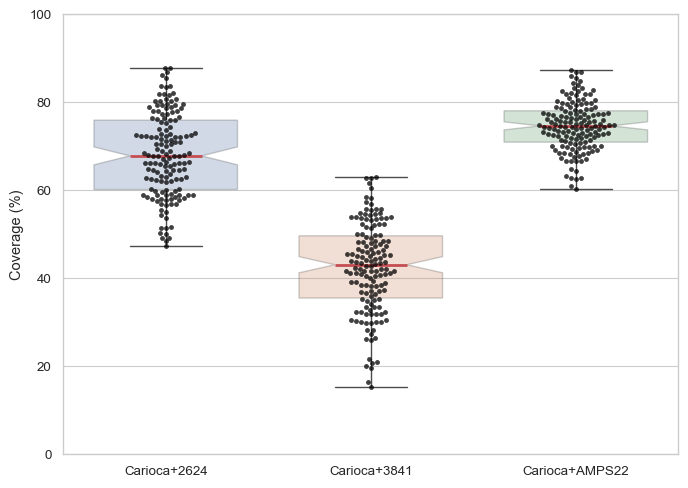

In [11]:
# Visual summary: notched box plots (the notch approximates a 95% CI for
# the median; McGill, Tukey & Larsen, 1978) overlaid with the individual
# observations (swarm plot).
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=data,
    x='File Name',
    y='Coverage Percentage',
    hue='File Name',   # hue is used only to colour each group differently
    legend=False,
    dodge=False,
    notch=True,
    width=0.7,
    medianprops={'color': 'r', 'linewidth': 2},
    boxprops={'alpha': 0.275},
)

sns.swarmplot(
    data=data,
    x='File Name',
    y='Coverage Percentage',
    color='black',
    alpha=0.75,
    size=3.5,
)

ax.set_xlabel('')
ax.set_ylabel('Coverage (%)')
ax.set_ylim(0, 100)   # coverage is bounded between 0 and 100 %

fig.tight_layout()
fig.savefig('coverage.svg', format='svg', bbox_inches='tight')
plt.show()


## References

- Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65&ndash;70.
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association*, 47(260), 583&ndash;621.
- McGill, R., Tukey, J. W., & Larsen, W. A. (1978). Variations of box plots. *The American Statistician*, 32(1), 12&ndash;16.
- Phipson, B., & Smyth, G. K. (2010). Permutation P-values should never be zero: calculating exact P-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.

---

*Created by Evgenii A. Kirichek 
<br>Notebook automatically reviewed and commented by DeepSeek V4-Pro*

---